In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/heart-disease/"
    "processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv(url, names=columns, na_values="?")

print("Dataset shape:", df.shape)
display(df.head())
display(df.isna().sum())

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [3]:
df["target"] = (df["num"] > 0).astype(int)
X = df.drop(columns = ["num", "target"])
y = df["target"]
num_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
print("X shape: ",X.shape)
print("y shape:", y.shape)
print("Target counts:\n", y.value_counts().sort_index())
print("Unlisted features:", set(X.columns) - set(num_features + cat_features))
print("Extra features:", set(num_features + cat_features) - set(X.columns))

X shape:  (303, 13)
y shape: (303,)
Target counts:
 target
0    164
1    139
Name: count, dtype: int64
Unlisted features: set()
Extra features: set()


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\n Training target proportions:")
display(y_train.value_counts(normalize= True).sort_index())
print("Testing target proportions:")
display(y_test.value_counts(normalize=True).sort_index())

X_train: (242, 13)
X_test: (61, 13)

 Training target proportions:


target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Testing target proportions:


target
0    0.540984
1    0.459016
Name: proportion, dtype: float64

In [9]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, num_features),
    ("cat", categorical_pipeline, cat_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

model

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [10]:
model.fit(X_train, y_train)
print("Model training completed.!")

Model training completed.!


Accuracy: 0.8852

 Classification report
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

COnfusion matrix (rows = true, columns = predicted):
[[28  5]
 [ 2 26]]


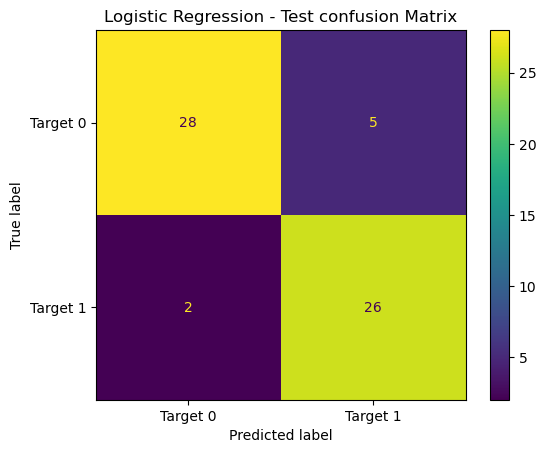

ROC-AUC: 0.9665


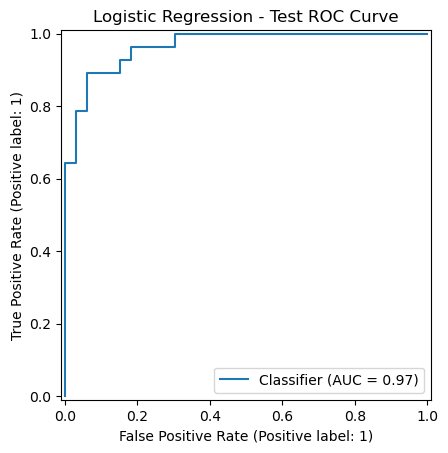

In [17]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\n Classification report")
print(classification_report(y_test, y_pred, zero_division=0))
print("COnfusion matrix (rows = true, columns = predicted):")
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(cm)
ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels=["Target 0", "Target 1"]
).plot()
plt.title("Logistic Regression - Test confusion Matrix")
plt.show()
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("Logistic Regression - Test ROC Curve")
plt.show()

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
#1. create 5 - fold stratified cross validation
cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)
cv_score = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)
print("Fold Scores:", cv_score)
print("Mean CV accuracy", cv_score.mean())
print("Standard Deviation:", cv_score.std())

Fold Scores: [0.83673469 0.85714286 0.85416667 0.83333333 0.85416667]
Mean CV accuracy 0.8471088435374149
Standard Deviation: 0.009976921631744011


In [ ]:

from pathlib import Path
import joblib

model_path = Path(
    r"C:\Users\Admin\Desktop\DS_Course\Heart_Disease_project\ML\heart_disease_pipeline.joblib"
)

joblib.dump(model, model_path)

print("Model saved successfully!")
print(model_path)


: 